In [10]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import pathlib
import pandas as pd

from tensorflow import keras
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPooling2D, UpSampling2D
import tensorboard
%matplotlib inline

In [2]:
#Time series data
#Tokenizing (using packages to map each word to a number), injected to the algorithm
#Embedding  

#Load MNIST dataset 
#Labels are omitted with linear units (Gaussian Distribution) since autoencoders are unsupervised
(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()


In [3]:
#Dataset Loader and Preprocessor
x_train = x_train.astype('float32')/255.0
x_test = x_test.astype('float32')/255.0

x_train = np.reshape(x_train, (len(x_train), 28, 28, 1))
x_test = np.reshape(x_test, (len(x_test), 28, 28, 1))


print('Training Shape: ', x_train.shape)
print('Testing Shape: ', x_test.shape)

Training Shape:  (60000, 28, 28, 1)
Testing Shape:  (10000, 28, 28, 1)


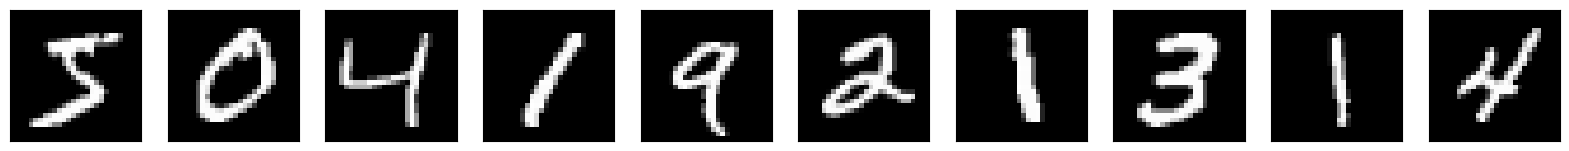

In [4]:

#Visualization Function 
#Function displays the first and images from dataset X in grayscale
def display_image(X, n=10):
    plt.figure(figsize=(20,2))
    for i in range(n):
        ax = plt.subplot(1, n, i+1)
        plt.imshow(X[i].reshape(28,28), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)
    plt.show()

# Displays the sample clean images from the given dataset
display_image(x_train, n=10)
    

Original Clean Images: 


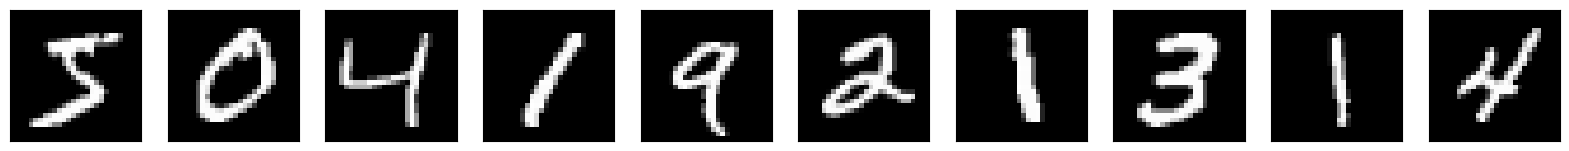

Synthetically Noisy Input: 


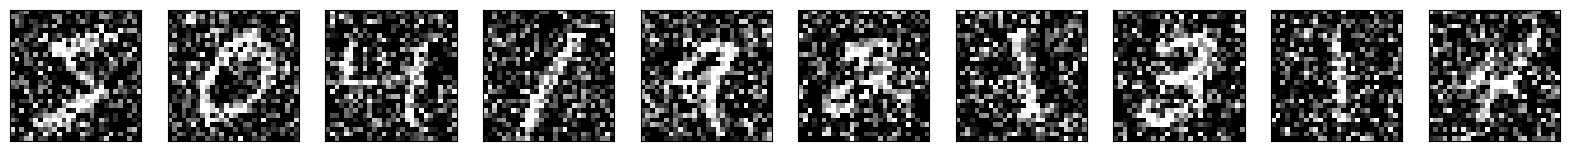

In [5]:
# Noise Generation (Synthetic Noise Generation) 
# Adds Gaussian noise to the dataset to simulate real-world noises (artifacts)

noise_factor = 0.5

#Add Zero-mean normal distribution noise
x_train_noise = x_train + noise_factor*np.random.normal(loc=0.0, scale=1.0, size=x_train.shape)
x_test_noise = x_test + noise_factor*np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)

#Clip values to maintain the valid pixel range between 0.0, 1.0 -> [0.0, 1.0]
x_train_noise = np.clip(x_train_noise, 0.0, 1.0)
x_test_noise = np.clip(x_test_noise, 0.0, 1.0)

#Displaying clean versus noisy comparisions 
print('Original Clean Images: ')
display_image(x_train, n=10)

print('Synthetically Noisy Input: ')
display_image(x_train_noise, n=10)


In [14]:
# Using Hyperparameters and Model Configuration 

#Image width and height in pixel
IMG_SIZE = 28

#Number of trianing epochs
NB_EPOCHS_DENOISE = 20

#Batch size for mini-batch SGD
BATCH_SIZE = 128

#Target Path for model saving
SAV_MODEL_DENOISE = 'denoiser.keras'

In [7]:
# Constructing the Convolutional Denoising Autoencoder 
# Constructs the encoder and decoder using ...
#........ Convolutional Sampling Operations
#........ Spatial Sampling Operations

# Encoder - section
input_img = Input(shape=(28,28,1), name='encoder_input')

# Converting block 1 (28, 28, 1) to (28, 28, 32), then to (14, 14, 32)
x = Conv2D(32, (3,3), activation='relu', padding='same')(input_img)
x = MaxPooling2D((2, 2), padding='same')(x)

#converting block 2 (14,14,32) to (14,14,32) and then to (7,7,32)
x = Conv2D(32, (3,3), activation = 'relu', padding = 'same')(x)
encoded = MaxPooling2D((2,2), padding='same')(x)

# Decoder - section
# Converts Block 1 (7,7,32) to (7,7,32) and then to (14,14,32)
x = Conv2D(32, (3,3), activation='relu', padding='same')(encoded)
x = UpSampling2D((2,2))(x)

# Reverse (DeConv) Block 2 (14,14,32) to (14,14,32) and then to (28,28,32)
x = Conv2D(32, (3,3), activation='relu', padding='same')(x)
x = UpSampling2D((2,2))(x)

# Reconcstruction Layer (28,28, 32) constructs to (28,28,1)
decoded = Conv2D(1, (3,3), activation = 'sigmoid', padding='same')(x)

#Instantiate and Compile full autoencoder Model
autoencoder = Model(inputs=input_img, outputs = decoded, name = 'convolutional_denoising_autoencoder')
autoencoder.compile(optimizer='adam', loss = 'binary_crossentropy')
autoencoder.summary()


Model: "convolutional_denoising_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,353 (110.75 KB)

 Trainable params: 28,353 (110.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - loss: 0.1737 - val_loss: 0.1174
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 45s 96ms/step - loss: 0.1145 - val_loss: 0.1096
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 45s 96ms/step - loss: 0.1089 - val_loss: 0.1060
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 83ms/step - loss: 0.1058 - val_loss: 0.1037
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 42s 89ms/step - loss: 0.1037 - val_loss: 0.1020
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 51s 109ms/step - loss: 0.1022 - val_loss: 0.1011
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 68s 144ms/step - loss: 0.1010 - val_loss: 0.1002
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 67s 141ms/step - loss: 0.1001 - val_loss: 0.0993
Epoch 9/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 46s 98ms/step - loss: 0.0994 - val_loss: 0.0988
Epoch 10/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 60s 128ms/step - loss: 0.0988 - val_loss: 0.0983
Epoch 11/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 41s 87ms/step - loss: 0.0984 - val_loss: 0.0979
Epoch 12/20
469/469 ━━━━━

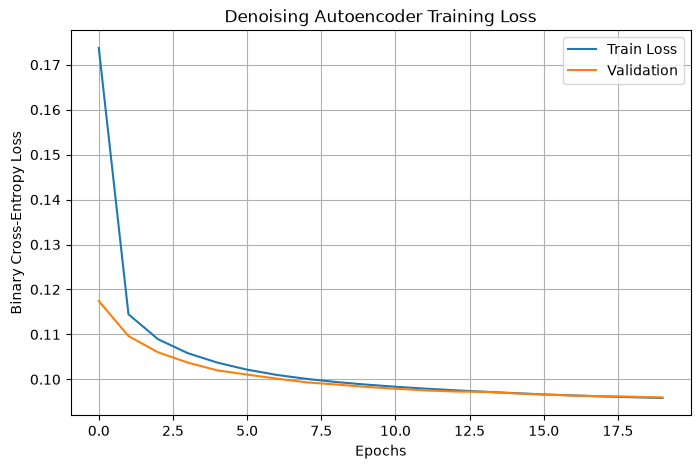

In [8]:
# Training and Evaluation 
# Training the autoencoder to map noisy inputs to clean ground-truth images

#load_ext TensorBoard

# Fit the autoencoder model
history = autoencoder.fit(x_train_noise, 
                          x_train, 
                          epochs=NB_EPOCHS_DENOISE,
                         batch_size = BATCH_SIZE,
                         shuffle = True,
                         validation_data = (x_test_noise, x_test),
                         callbacks = [tf.keras.callbacks.TensorBoard(log_dir='/tmp/tb', 
                                                                     histogram_freq = 0,
                                                                    write_graph = False)]
                         )

#Plot trianing and validation loss curves 
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label = 'Validation')
plt.title('Denoising Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()
plt.grid(True)
plt.show()

Model Successfuly Saved to denoiser.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Noisy Input Images (Test Set): 


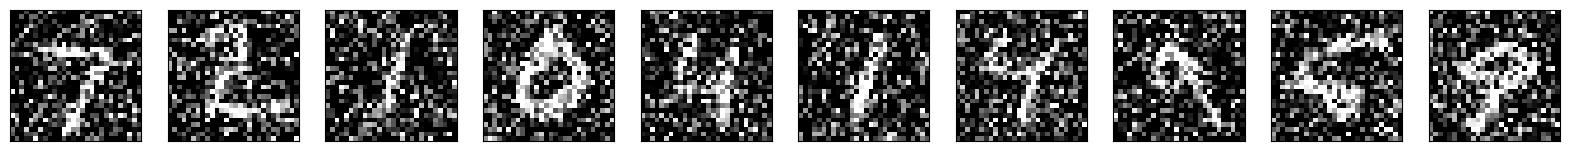

Denoised Reconstruct Outputs (Model Predictions): 


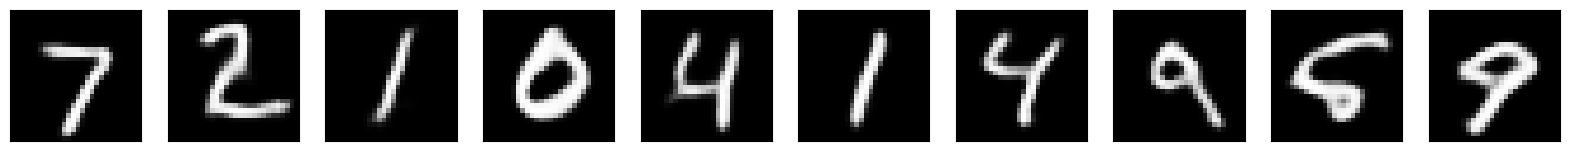

In [15]:
# Model Saving, Inference & Evaluation 
# Saves the trained weights and test the reconstruction quality on unseen noisy images.

# Save the model artifact locally 

autoencoder.save(SAV_MODEL_DENOISE)
print(f'Model Successfuly Saved to {SAV_MODEL_DENOISE}')

# Generate denoised outputs on test dataset
decoded_imgs = autoencoder.predict(x_test_noise)

#visualize qualitative results 
print('Noisy Input Images (Test Set): ')
display_image(x_test_noise, n=10)

print('Denoised Reconstruct Outputs (Model Predictions): ')
display_image(decoded_imgs, n=10)
